[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/04_thermostats_barostats_ensembles.ipynb)

# 04 · Thermostats, Barostats, and Ensembles (NVE, NVT, NPT)

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~60 min*

Experiments happen at constant **temperature** and **pressure**, not at constant energy. In this notebook we
measure temperature from atomic velocities, compare the thermostats you will meet in MD papers (velocity
rescaling, Andersen, Langevin, Nosé–Hoover), check which ones give the *right* fluctuations, and finally
run a box of water at constant pressure with a Monte Carlo barostat to compute its density.

**Learning objectives.** By the end of this notebook you will be able to:

- define the NVE, NVT, and NPT ensembles and say which one an experiment corresponds to
- compute the instantaneous temperature from kinetic energy and degrees of freedom
- compare thermostats and recognize one that gives the wrong ensemble
- run NPT water with a Monte Carlo barostat and read off its density and pressure fluctuations

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'openmm'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Ensembles in one table

| Ensemble | Fixed | Fluctuates | MD tool | Typical use |
|---|---|---|---|---|
| **NVE** (microcanonical) | atoms, volume, energy | temperature, pressure | plain Verlet | testing integrators (Notebook 03) |
| **NVT** (canonical) | atoms, volume, temperature | energy, pressure | thermostat | equilibration, fixed-box studies |
| **NPT** (isothermal–isobaric) | atoms, pressure, temperature | energy, volume | thermostat + barostat | most biomolecular production runs |

**Temperature** in MD is defined from the kinetic energy: $\tfrac12 N_{df} k_B T = \sum_i \tfrac12 m_i v_i^2$,
where $N_{df}$ is the number of degrees of freedom ($3N$ minus constraints minus 3 for the fixed centre of mass).
Because it is computed from a finite number of atoms, the *instantaneous* temperature fluctuates even when
the thermostat is perfect. Statistical mechanics predicts how much: in the canonical ensemble
$\sigma_T / \langle T \rangle = \sqrt{2 / N_{df}}$.

## 2. A test system: liquid argon at 120 K

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmm
from openmm import app, unit

SIGMA, EPS, MASS, KB = 0.3405, 0.996, 39.948, 0.0083144626
N_CELL, T0 = 4, 120.0
N = 4 * N_CELL**3                                   # 256 atoms
L = (N / 0.8) ** (1 / 3) * SIGMA

def argon_system():
    system = openmm.System()
    system.setDefaultPeriodicBoxVectors(openmm.Vec3(L, 0, 0), openmm.Vec3(0, L, 0), openmm.Vec3(0, 0, L))
    nbf = openmm.NonbondedForce()
    nbf.setNonbondedMethod(openmm.NonbondedForce.CutoffPeriodic)
    nbf.setCutoffDistance(2.5 * SIGMA)
    nbf.setUseSwitchingFunction(True); nbf.setSwitchingDistance(2.2 * SIGMA)
    for _ in range(N):
        system.addParticle(MASS); nbf.addParticle(0.0, SIGMA, EPS)
    system.addForce(nbf)
    system.addForce(openmm.CMMotionRemover())
    return system

a = L / N_CELL
base = np.array([[0, 0, 0], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]])
grid = np.array([[i, j, k] for i in range(N_CELL) for j in range(N_CELL) for k in range(N_CELL)])
x0 = ((grid[:, None] + base[None]).reshape(-1, 3) + 0.25) * a

# melt and equilibrate with a Langevin thermostat so every method starts from the same liquid
integ = openmm.LangevinMiddleIntegrator(T0, 5.0, 0.005); integ.setRandomNumberSeed(1)
ctx = openmm.Context(argon_system(), integ, openmm.Platform.getPlatformByName("CPU"))
ctx.setPositions(x0); ctx.setVelocitiesToTemperature(T0, 1)
integ.step(4000)
start = ctx.getState(getPositions=True, getVelocities=True)
N_DF = 3 * N - 3
print(f"{N} argon atoms, {N_DF} degrees of freedom, expected sigma_T/T = {np.sqrt(2 / N_DF):.4f}")

256 argon atoms, 765 degrees of freedom, expected sigma_T/T = 0.0511


## 3. Four thermostats side by side

- **Velocity rescaling** (naive): multiply all velocities so the temperature is exactly $T_0$ at every step. It is
  intuitive, and it is **wrong**: it suppresses temperature fluctuations, so it does not sample the canonical ensemble.
  (Berendsen's weak-coupling thermostat has the same flaw, more mildly. The stochastic *v-rescale* thermostat of
  Bussi *et al.* in GROMACS fixes it.)
- **Andersen**: every so often, an atom gets a fresh velocity drawn from the Maxwell–Boltzmann distribution.
- **Langevin**: every atom feels friction plus random kicks whose size is tied to the friction
  (fluctuation–dissipation theorem). OpenMM's `LangevinMiddleIntegrator` is the recommended default.
- **Nosé–Hoover**: a deterministic "heat bath" variable couples to the velocities.

In [3]:
def run(name, n_steps=6000, dt=0.005, every=10):
    system = argon_system()
    if name == "Andersen":
        system.addForce(openmm.AndersenThermostat(T0, 5.0)); integ = openmm.VerletIntegrator(dt)
    elif name == "Langevin":
        integ = openmm.LangevinMiddleIntegrator(T0, 1.0, dt)
    elif name == "Nose-Hoover":
        integ = openmm.NoseHooverIntegrator(T0, 1.0, dt)
    else:                                            # NVE and naive rescaling
        integ = openmm.VerletIntegrator(dt)
    if hasattr(integ, "setRandomNumberSeed"):
        integ.setRandomNumberSeed(2)
    c = openmm.Context(system, integ, openmm.Platform.getPlatformByName("CPU"))
    c.setPositions(start.getPositions()); c.setVelocities(start.getVelocities())
    temps = []
    for step in range(0, n_steps, every):
        integ.step(every)
        st = c.getState(getEnergy=True, getVelocities=(name == "rescaling"))
        ke = st.getKineticEnergy().value_in_unit(unit.kilojoule_per_mole)
        if name == "rescaling":
            v = st.getVelocities(asNumpy=True) * np.sqrt(T0 / (2 * ke / (N_DF * KB)))
            c.setVelocities(v)
            ke = c.getState(getEnergy=True).getKineticEnergy().value_in_unit(unit.kilojoule_per_mole)
        temps.append(2 * ke / (N_DF * KB))
    v = c.getState(getVelocities=True).getVelocities(asNumpy=True).value_in_unit(unit.nanometer / unit.picosecond)
    return np.array(temps), v

t0 = time.time()
traces, vels, rows = {}, {}, []
for name in ["NVE", "rescaling", "Andersen", "Langevin", "Nose-Hoover"]:
    T, v = run(name)
    traces[name], vels[name] = T, v
    rows.append({"method": name, "mean T (K)": T.mean(), "std T (K)": T.std(), "std T / mean T": T.std() / T.mean()})
summary = pd.DataFrame(rows).set_index("method")
summary["expected (canonical)"] = np.sqrt(2 / N_DF)
print(f"5 x 30 ps in {time.time() - t0:.0f} s")
summary.round(4)

5 x 30 ps in 15 s


,mean T (K),std T (K),std T / mean T,expected (canonical)
method,,,,
NVE,117.9049,3.2975,0.0280,0.0511
rescaling,120.0012,0.0020,0.0000,0.0511
Andersen,119.4571,6.3751,0.0534,0.0511
Langevin,118.4668,5.7550,0.0486,0.0511
Nose-Hoover,119.9026,5.9039,0.0492,0.0511


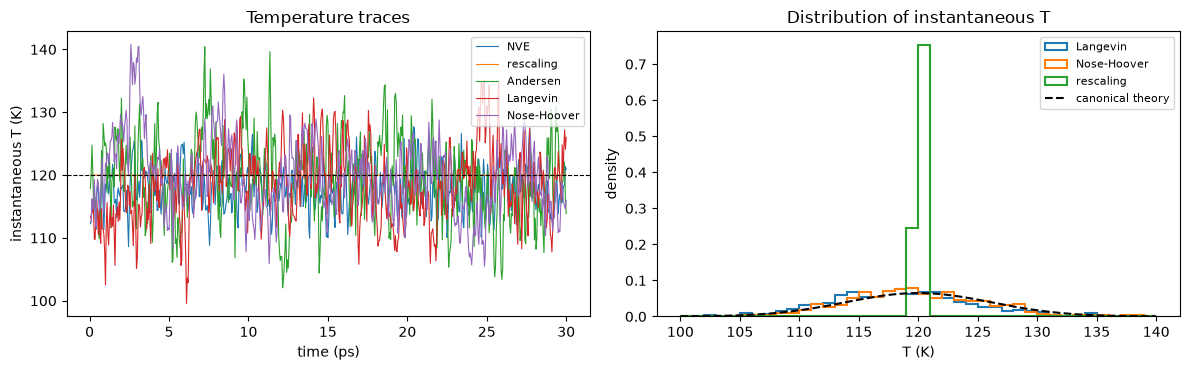

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
t = np.arange(1, len(traces["NVE"]) + 1) * 0.05
for name, T in traces.items():
    ax[0].plot(t, T, lw=0.8, label=name)
ax[0].axhline(T0, color="k", ls="--", lw=0.8)
ax[0].set(xlabel="time (ps)", ylabel="instantaneous T (K)", title="Temperature traces"); ax[0].legend(fontsize=8)
bins = np.linspace(100, 140, 41)
for name in ["Langevin", "Nose-Hoover", "rescaling"]:
    ax[1].hist(traces[name], bins=bins, histtype="step", lw=1.5, density=True, label=name)
g = np.linspace(100, 140, 200); s = T0 * np.sqrt(2 / N_DF)
ax[1].plot(g, np.exp(-(g - T0) ** 2 / (2 * s * s)) / (s * np.sqrt(2 * np.pi)), "k--", label="canonical theory")
ax[1].set(xlabel="T (K)", ylabel="density", title="Distribution of instantaneous T"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

NVE has no thermostat, so its average temperature is whatever the starting energy gives, and its fluctuations
are not canonical either. Andersen, Langevin, and Nosé–Hoover all hold the average at 120 K **and** give
fluctuations close to the theoretical $\sqrt{2/N_{df}}$. Naive rescaling pins the temperature with no
fluctuations at all: it looks "perfectly controlled" but samples the wrong ensemble. A thermostat that keeps
the temperature too constant is a red flag.

**Practical notes.** Stochastic thermostats (Andersen, Langevin) disturb the dynamics, so diffusion constants
and other time-dependent properties shrink when the coupling is strong; use a small friction (1/ps) and
compare with NVE if dynamics matter. For structure and thermodynamics they are excellent and very robust.

## 4. Velocities follow the Maxwell–Boltzmann distribution

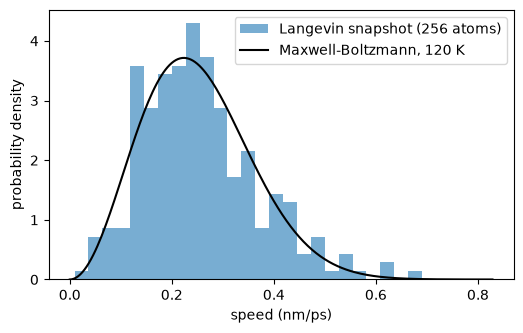

mean speed: simulation 0.255 nm/ps, theory 0.252 nm/ps


In [5]:
v = vels["Langevin"]
speed = np.linalg.norm(v, axis=1)
c_ = np.linspace(0, speed.max() * 1.2, 200)
mb = 4 * np.pi * c_**2 * (MASS / (2 * np.pi * KB * T0)) ** 1.5 * np.exp(-MASS * c_**2 / (2 * KB * T0))
plt.figure(figsize=(6, 3.5))
plt.hist(speed, bins=25, density=True, alpha=0.6, label="Langevin snapshot (256 atoms)")
plt.plot(c_, mb, "k-", label="Maxwell-Boltzmann, 120 K")
plt.xlabel("speed (nm/ps)"); plt.ylabel("probability density"); plt.legend(); plt.show()
print(f"mean speed: simulation {speed.mean():.3f} nm/ps, theory {np.sqrt(8 * KB * T0 / (np.pi * MASS)):.3f} nm/ps")

## 5. NPT: a box of water at 1 bar

Now real water: about 550 TIP3P-FB molecules built by OpenMM's `Modeller`. A **Monte Carlo barostat** tries a small
random change of box volume every 25 steps and accepts or rejects it with the NPT Metropolis criterion, so the
volume fluctuates around the value that gives 1 bar on average. We use PME electrostatics (Notebook 05).

In [6]:
ff = app.ForceField("amber14/tip3pfb.xml")
modeller = app.Modeller(app.Topology(), [])
modeller.addSolvent(ff, boxSize=openmm.Vec3(2.6, 2.6, 2.6) * unit.nanometer)
n_water = modeller.topology.getNumResidues()
system = ff.createSystem(modeller.topology, nonbondedMethod=app.PME, nonbondedCutoff=0.9 * unit.nanometer)
barostat = openmm.MonteCarloBarostat(1.0 * unit.bar, 300 * unit.kelvin, 25)
system.addForce(barostat)
integ = openmm.LangevinMiddleIntegrator(300 * unit.kelvin, 1 / unit.picosecond, 0.002 * unit.picoseconds)
integ.setRandomNumberSeed(3)
sim = app.Simulation(modeller.topology, system, integ, openmm.Platform.getPlatformByName("CPU"))
sim.context.setPositions(modeller.positions)
sim.minimizeEnergy()
sim.context.setVelocitiesToTemperature(300 * unit.kelvin, 3)

mass_g = sum(system.getParticleMass(i).value_in_unit(unit.dalton) for i in range(system.getNumParticles())) / 6.02214076e23
rows, t0 = [], time.time()
for k in range(150):                                  # 150 x 0.2 ps = 30 ps
    sim.step(100)
    st = sim.context.getState(getEnergy=True)
    vol = st.getPeriodicBoxVolume().value_in_unit(unit.nanometer**3)
    rows.append({"t_ps": (k + 1) * 0.2, "volume_nm3": vol, "density_g_cm3": mass_g / (vol * 1e-21),
                 "pressure_bar": barostat.computeCurrentPressure(sim.context).value_in_unit(unit.bar),
                 "potential_kJmol": st.getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)})
npt = pd.DataFrame(rows)
print(f"{n_water} waters, {system.getNumParticles()} atoms: 30 ps NPT in {time.time() - t0:.0f} s")

564 waters, 1692 atoms: 30 ps NPT in 113 s


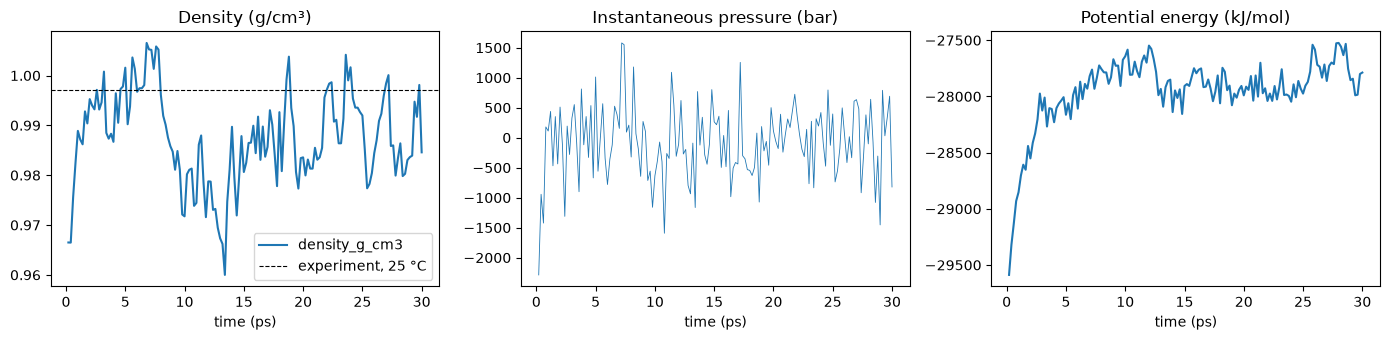

after 5 ps: density 0.9871 ± 0.0093 g/cm3, pressure -67 ± 576 bar (target 1 bar)


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
npt.plot(x="t_ps", y="density_g_cm3", ax=ax[0], legend=False, title="Density (g/cm³)")
ax[0].axhline(0.997, color="k", ls="--", lw=0.8, label="experiment, 25 °C"); ax[0].legend()
npt.plot(x="t_ps", y="pressure_bar", ax=ax[1], legend=False, lw=0.6, title="Instantaneous pressure (bar)")
npt.plot(x="t_ps", y="potential_kJmol", ax=ax[2], legend=False, title="Potential energy (kJ/mol)")
for a_ in ax: a_.set_xlabel("time (ps)")
plt.tight_layout(); plt.show()
prod = npt[npt.t_ps > 5]
print(f"after 5 ps: density {prod.density_g_cm3.mean():.4f} ± {prod.density_g_cm3.std():.4f} g/cm3, "
      f"pressure {prod.pressure_bar.mean():.0f} ± {prod.pressure_bar.std():.0f} bar (target 1 bar)")

Two lessons. First, the density settles near the experimental value of water (TIP3P-FB was fitted to
reproduce it). Second, the **instantaneous pressure** fluctuates by hundreds of bar in a box this small;
only its *average* is meaningful, and with a short run even the average is noisy. Never judge a barostat by
a single pressure reading. Larger boxes fluctuate less (relative fluctuations scale as $1/\sqrt{N}$).

**Which barostat?** Monte Carlo (OpenMM, AMBER) and stochastic cell rescaling or Parrinello–Rahman (GROMACS)
give the correct NPT ensemble. Berendsen pressure coupling is fine for early equilibration but, like the
Berendsen thermostat, suppresses fluctuations, so avoid it in production.

### ✏️ Exercise 1

Repeat the Langevin argon run with a much **stronger friction** (50/ps instead of 1/ps). Does the average
temperature change? Does the size of the fluctuations change? (Edit a copy of `run`, or temporarily add a
`friction` argument.)

In [8]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
system = argon_system()
integ = openmm.LangevinMiddleIntegrator(T0, 50.0, 0.005); integ.setRandomNumberSeed(5)
c = openmm.Context(system, integ, openmm.Platform.getPlatformByName("CPU"))
c.setPositions(start.getPositions()); c.setVelocities(start.getVelocities())
T = []
for _ in range(600):
    integ.step(10)
    T.append(2 * c.getState(getEnergy=True).getKineticEnergy()._value / (N_DF * KB))
print(f"mean {np.mean(T):.1f} K, std/mean {np.std(T) / np.mean(T):.4f}")
# Same distribution: friction changes the dynamics, not the equilibrium ensemble.
```

</details>

### ✏️ Exercise 2

Compute the **isothermal compressibility** of water from the volume fluctuations:
$\kappa_T = \langle \delta V^2 \rangle / (k_B T \langle V \rangle)$. Use $k_BT$ in J and V in m³ (1 nm³ = 1e-27 m³),
discard the first 5 ps, and compare with the experimental value 4.5e-10 Pa⁻¹. Why is the agreement rough?

In [9]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
V = prod.volume_nm3.values * 1e-27
kT = 1.380649e-23 * 300
kappa = V.var() / (kT * V.mean())
print(f"kappa_T = {kappa:.2e} 1/Pa (experiment 4.5e-10)")
# 25 ps and ~550 waters give a noisy variance; fluctuation properties need long runs.
```

</details>

### ✏️ Exercise 3

Change the barostat target to **1000 bar** (`barostat.setDefaultPressure(1000 * unit.bar)` and
`sim.context.setParameter(openmm.MonteCarloBarostat.Pressure(), 1000)`) and run 10 ps more. How much does the
density increase?

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
sim.context.setParameter(openmm.MonteCarloBarostat.Pressure(), 1000.0)
d = []
for _ in range(50):
    sim.step(100)
    d.append(mass_g / (sim.context.getState().getPeriodicBoxVolume().value_in_unit(unit.nanometer**3) * 1e-21))
print(f"density at 1000 bar (last 5 ps): {np.mean(d[25:]):.4f} g/cm3")
```

</details>

## Key takeaways

- NVE conserves energy; NVT uses a thermostat; NPT adds a barostat and matches most experiments.
- Instantaneous temperature and pressure *should* fluctuate; the expected size follows from statistical mechanics.
- Langevin, Andersen, Nosé–Hoover, v-rescale, and Monte Carlo barostats sample the right ensembles; naive rescaling and Berendsen do not.
- Water density from a short NPT run is a quick sanity check of a water model and barostat.

**Next:** [05 · Periodic boundaries, cutoffs, and PME](05_periodic_boundaries_pme.ipynb).